# Práctica 2: Aprendizaje No Supervisado

### Izan Cuesta Corbí

#### Importación de librerías

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons, make_circles, make_blobs, load_digits, fetch_kddcup99
from sklearn.preprocessing import StandardScaler, LabelEncoder
import umap
from sklearn.cluster import KMeans, SpectralClustering, DBSCAN, OPTICS
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, silhouette_score, precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
import time
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.ensemble import IsolationForest

## Parte 1: Clustering

#### Datasets Sintéticos

In [13]:
np.random.seed(42)

# ── Escenario 1: Blobs isotrópicas ──────────────────────────────────────────
X_blobs, y_blobs = make_blobs(n_samples=1500, centers=3, cluster_std=1.0,
                               random_state=42)
X_blobs = StandardScaler().fit_transform(X_blobs)

# ── Escenario 2: Lunas entrelazadas ─────────────────────────────────────────
X_moons, y_moons = make_moons(n_samples=1500, noise=0.05, random_state=42)
X_moons = StandardScaler().fit_transform(X_moons)

# ── Escenario 3: Círculos concéntricos ──────────────────────────────────────
X_circles, y_circles = make_circles(n_samples=1500, noise=0.05, factor=0.5,
                                     random_state=42)
X_circles = StandardScaler().fit_transform(X_circles)

# ── Escenario 4: Clusters de densidad variable ──────────────────────────────
X_dense = np.vstack([
    np.random.randn(500, 2) * 0.3 + [0, 0],     # cluster denso
    np.random.randn(500, 2) * 1.5 + [6, 0],      # cluster disperso
    np.random.randn(100, 2) * 0.5 + [3, 4],      # cluster pequeño y denso
])
y_dense = np.array([0]*500 + [1]*500 + [2]*100)
X_dense = StandardScaler().fit_transform(X_dense)

# ── Escenario 5: Blobs anisotrópicas con ruido ──────────────────────────────
X_aniso_base, y_aniso_base = make_blobs(n_samples=1000, centers=3, random_state=42)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso_base = X_aniso_base @ transformation
n_noise = 100
noise_pts = np.random.uniform(X_aniso_base.min(axis=0) - 1,
                               X_aniso_base.max(axis=0) + 1,
                               size=(n_noise, 2))
X_aniso = np.vstack([X_aniso_base, noise_pts])
y_aniso = np.concatenate([y_aniso_base, np.full(n_noise, -1)])
X_aniso = StandardScaler().fit_transform(X_aniso)


scenarios = {
    'Blobs':              (X_blobs,   y_blobs,   3),
    'Moons':              (X_moons,   y_moons,   2),
    'Circles':            (X_circles, y_circles,  2),
    'Densidad variable':  (X_dense,   y_dense,    3),
    'Anisotrópico+ruido': (X_aniso,   y_aniso,    3),
}

#### Dataset real: Digits con UMAP

In [14]:
digits = load_digits()
X_digits_raw = digits.data       # (1797, 64)
y_digits     = digits.target     # 10 clases (0-9)

reducer   = umap.UMAP(n_components=2, random_state=42, n_neighbors=15,
                       min_dist=0.1)
X_digits  = reducer.fit_transform(X_digits_raw)
X_digits  = StandardScaler().fit_transform(X_digits)

c:\Users\pepov\anaconda\envs\Aprendizaje_AV\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


### 1.1 K-Means (Referencia)

##### Sobre los escenarios sintéticos

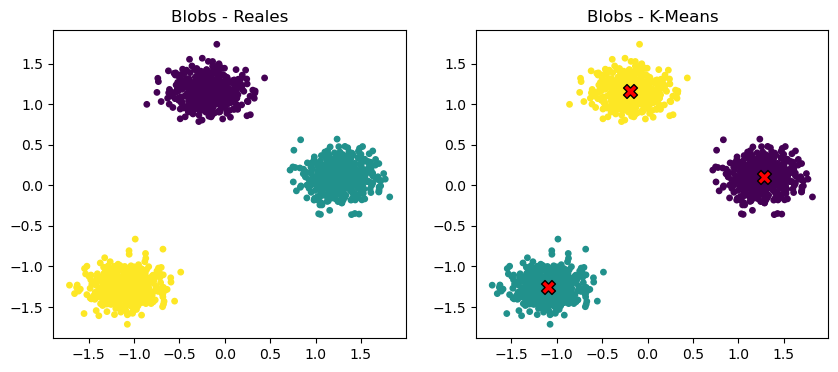

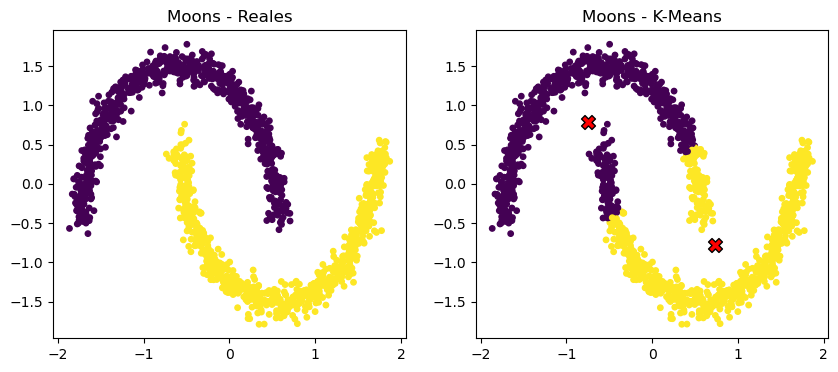

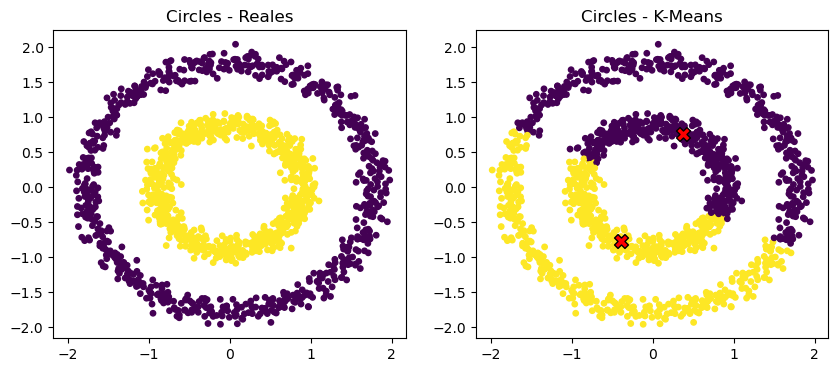

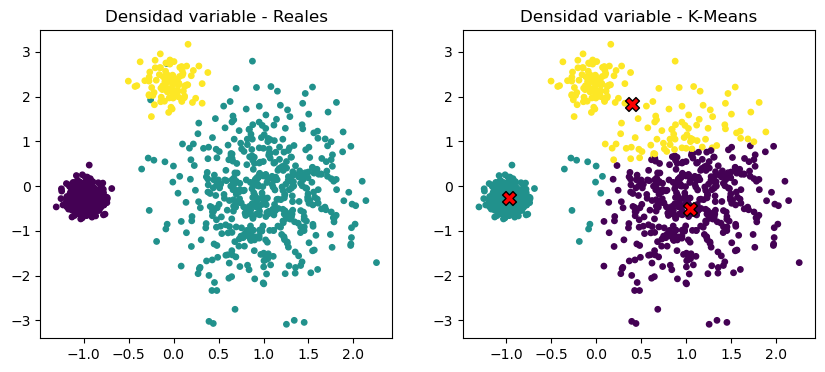

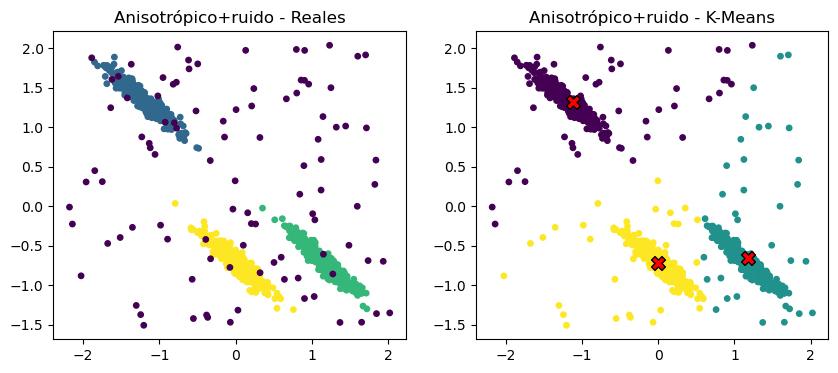

,Escenario,K,ARI,NMI,Silhouette
0,Blobs,3,1.0000,1.0000,0.8441
1,Moons,2,0.4785,0.3803,0.4961
2,Circles,2,-0.0006,0.0000,0.3544
3,Densidad variable,3,0.8150,0.7853,0.6488
4,Anisotrópico+ruido,3,0.8507,0.8188,0.6812


In [59]:
resultados = []
best_labels_kmeans = {}

for nombre, (X, y, k) in scenarios.items():
    
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    y_pred = kmeans.fit_predict(X)
    
    best_labels_kmeans[nombre] = y_pred
    
    ari = adjusted_rand_score(y, y_pred)
    nmi = normalized_mutual_info_score(y, y_pred)
    sil = silhouette_score(X, y_pred)
    
    resultados.append({'Escenario': nombre, 'K': k, 'ARI': round(ari, 4), 'NMI': round(nmi, 4), 'Silhouette': round(sil, 4)})
    
    plt.figure(figsize=(10, 4))
    
    plt.subplot(1, 2, 1)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='viridis', s=15)
    plt.title(f'{nombre} - Reales')
    
    plt.subplot(1, 2, 2)
    plt.scatter(X[:, 0], X[:, 1], c=y_pred, cmap='viridis', s=15)
    plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], c='red', marker='X', s=100, edgecolor='black')
    plt.title(f'{nombre} - K-Means')
    
    plt.savefig(f'images/kmeans_{nombre}', dpi=300)
    plt.show()

df_kmeans = pd.DataFrame(resultados)
display(df_kmeans)

En este apartado aplicamos K-Means sobre cinco escenarios sintéticos utilizando el número real de clústeres, demostrando que la eficacia del algoritmo depende de la geometría de los datos. Obtenemos los mejores resultados en el escenario más sencillo, Blobs, alcanzando una segmentación perfecta con métricas máximas (ARI = 1.0 y NMI = 1.0). Por el contrario, el algoritmo fracasa por completo al enfrentarse a formas complejas, donde registramos resultados casi aleatorios en Circles (ARI = -0.0006) y malas agrupaciones en Moons (ARI = 0.4785), mientras que en los entornos de Densidad variable y Anisotrópico con ruido logramos un rendimiento subóptimo pero aceptable (ARI entre 0.81 y 0.85). Por último, comprobamos que las métricas internas pueden resultar engañosas, por ejemplo, en la puntuación Silhouette en Moons obtenemos un valor alto (0.4961) pese a la mala segmentación.

##### Sobre Digits

,Método,K,ARI,NMI,Silhouette,Tiempo (s)
0,K-Means,10,0.8248,0.8912,0.7737,0.0912


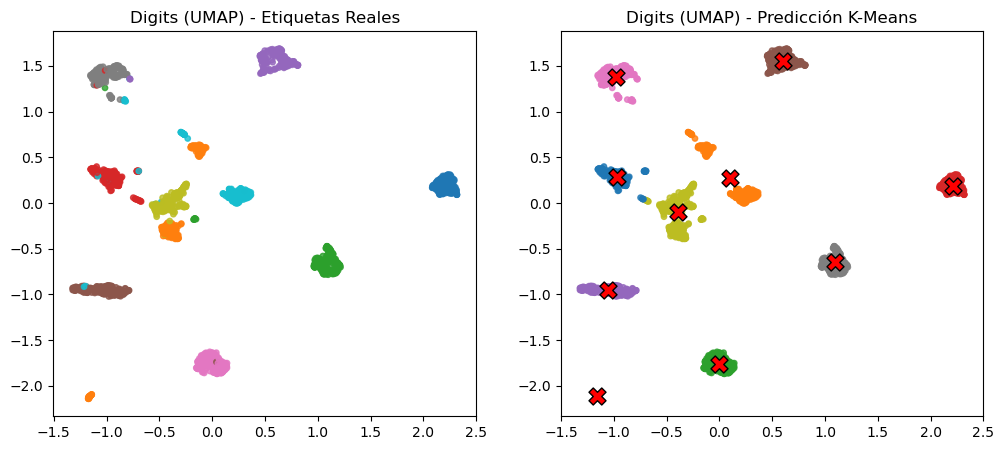

La inercia para K=10 es: 56.75276184082031


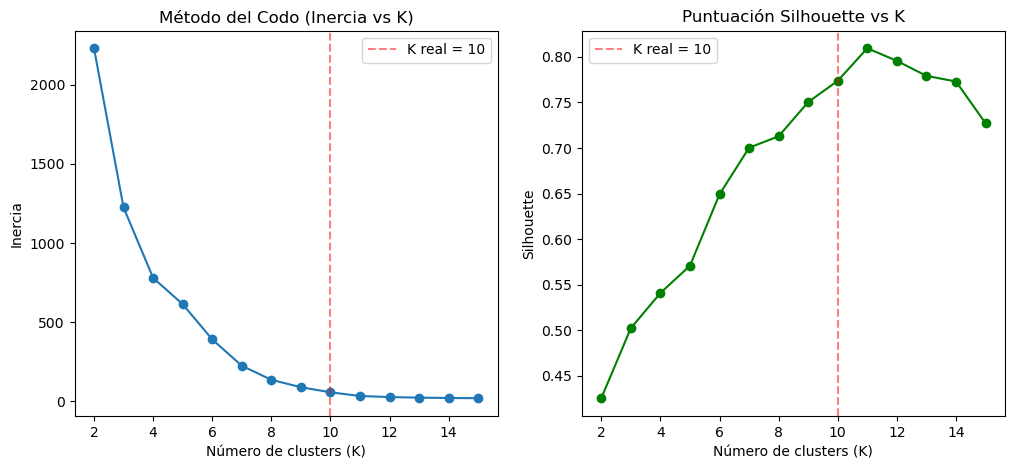

In [74]:
k_digits = 10

inicio = time.time()
kmeans_digits = KMeans(n_clusters=k_digits, random_state=42, n_init=10)
y_pred_digits = kmeans_digits.fit_predict(X_digits)
tiempo_kmeans_digits = round(time.time() - inicio, 4)

best_labels_kmeans_digits = y_pred_digits

ari_digits = adjusted_rand_score(y_digits, y_pred_digits)
nmi_digits = normalized_mutual_info_score(y_digits, y_pred_digits)
sil_digits = silhouette_score(X_digits, y_pred_digits)

df_kmeans_digits = pd.DataFrame([{
    'Método': 'K-Means',
    'K': k_digits,
    'ARI': round(ari_digits, 4),
    'NMI': round(nmi_digits, 4),
    'Silhouette': round(sil_digits, 4),
    'Tiempo (s)': tiempo_kmeans_digits
}])
display(df_kmeans_digits)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.scatter(X_digits[:, 0], X_digits[:, 1], c=y_digits, cmap='tab10', s=15, alpha=0.8)
plt.title('Digits (UMAP) - Etiquetas Reales')
plt.subplot(1, 2, 2)
plt.scatter(X_digits[:, 0], X_digits[:, 1], c=y_pred_digits, cmap='tab10', s=15, alpha=0.8)
plt.scatter(kmeans_digits.cluster_centers_[:, 0], kmeans_digits.cluster_centers_[:, 1],
            c='red', marker='X', s=150, edgecolor='black')
plt.title('Digits (UMAP) - Predicción K-Means')
plt.savefig('images/kmeans_digits.png', dpi=300)
plt.show()

inercias = []
silhouettes = []
rango_k = range(2, 16)

for k in rango_k:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    preds = km.fit_predict(X_digits)
    inercias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_digits, preds))

inercia_k10 = kmeans_digits.inertia_
print(f"La inercia para K=10 es: {inercia_k10}")

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(rango_k, inercias, marker='o')
plt.axvline(x=10, color='red', linestyle='--', alpha=0.5, label='K real = 10')
plt.title('Método del Codo (Inercia vs K)')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Inercia')
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(rango_k, silhouettes, marker='o', color='green')
plt.axvline(x=10, color='red', linestyle='--', alpha=0.5, label='K real = 10')
plt.title('Puntuación Silhouette vs K')
plt.xlabel('Número de clusters (K)')
plt.ylabel('Silhouette')
plt.legend()
plt.savefig('images/codo_y_silhouette', dpi=300)
plt.show()

En este apartado aplicamos K-Means sobre el dataset de Digits creando exactamente 10 clústeres (K=10). Con esta configuración logramos capturar la estructura principal de los datos, obteniendo un resultado decente (ARI = 0.8248). Mediante el análisis de las gráficas del método del codo y la puntuación Silhouette, comprobamos que nuestra configuración era subóptima y que el número ideal de agrupaciones era realmente K=11. Al obligar al algoritmo a formar estrictamente 10 conjuntos, provocamos que dos grupos distintos de la proyección se fusionaran incorrectamente en uno solo para cumplir con nuestra restricción impuesta, lo que explica directamente por qué la segmentación final no alcanza la perfección y limita el rendimiento de las métricas externas.

### 1.2 Clustering Espectral

##### Sobre los escenarios sintéticos

In [60]:
resultados_spectral = []
vecinos_a_probar = [5, 15]
best_labels_spectral = {}

for nombre, (X, y, k) in scenarios.items():
    for n_vecinos in vecinos_a_probar:
        
        spectral = SpectralClustering(
            n_clusters=k, 
            affinity='nearest_neighbors', 
            n_neighbors=n_vecinos, 
            random_state=42
        )
        y_pred = spectral.fit_predict(X)
        
        ari = adjusted_rand_score(y, y_pred)
        nmi = normalized_mutual_info_score(y, y_pred)
        sil = silhouette_score(X, y_pred)
        
        if nombre not in best_labels_spectral or ari > adjusted_rand_score(y, best_labels_spectral[nombre]):
            best_labels_spectral[nombre] = y_pred
        
        resultados_spectral.append({
            'Escenario': nombre,
            'n_neighbors': n_vecinos,
            'ARI': round(ari, 4),
            'NMI': round(nmi, 4),
            'Silhouette': round(sil, 4)
        })

df_spectral = pd.DataFrame(resultados_spectral)
display(df_spectral)

c:\Users\pepov\anaconda\envs\Aprendizaje_AV\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Users\pepov\anaconda\envs\Aprendizaje_AV\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Users\pepov\anaconda\envs\Aprendizaje_AV\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Users\pepov\anaconda\envs\Aprendizaje_AV\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Users\pepov\anaconda\envs\Aprendizaje_AV\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, sp

,Escenario,n_neighbors,ARI,NMI,Silhouette
0,Blobs,5,0.5695,0.7258,0.1624
1,Blobs,15,1.0000,1.0000,0.8441
2,Moons,5,0.0001,0.0090,-0.0687
3,Moons,15,1.0000,1.0000,0.3935
4,Circles,5,0.9814,0.9618,0.1092
5,Circles,15,1.0000,1.0000,0.1127
6,Densidad variable,5,0.8790,0.8567,0.6428
7,Densidad variable,15,0.9567,0.9293,0.6406
8,Anisotrópico+ruido,5,0.7815,0.7453,0.6495
9,Anisotrópico+ruido,15,0.8405,0.8076,0.6756


En este apartado aplicamos el algoritmo de Clustering Espectral sobre los escenarios sintéticos, evaluando el impacto del parámetro de vecinos (n_neighbors configurado a 5 y 15). Comprobamos que este método supera ampliamente a K-Means en las geometrías complejas y no convexas, logrando segmentaciones perfectas (ARI = 1.0000) en Moons y Circles, así como un rendimiento notablemente superior en el entorno de Densidad variable (ARI = 0.9567), demostrando su gran capacidad para aprovechar la continuidad espacial de los datos. Al comparar ambas configuraciones, observamos que el uso de 15 vecinos es muy superior en absolutamente todos los escenarios. Por el contrario, al restringir la conexión a solo 5 vecinos, observamos una caída en el rendimiento general pero especialmente en Moons, donde el ARI se desploma a 0.0001, y en Blobs, que cae a 0.5695.

##### Sobre Digits (K=10)

In [78]:
k_digits = 10
resultados_digits = []
best_labels_spectral_digits = None
best_ari_spectral_digits = -1
tiempo_spectral_digits = None

vecinos_a_probar = [5, 10, 15, 30, 50]

for nn in vecinos_a_probar:
    inicio = time.time()
    spectral_nn = SpectralClustering(
        n_clusters=k_digits,
        affinity='nearest_neighbors',
        n_neighbors=nn,
        random_state=42
    )
    y_pred = spectral_nn.fit_predict(X_digits)
    tiempo = round(time.time() - inicio, 4)

    ari = adjusted_rand_score(y_digits, y_pred)
    nmi = normalized_mutual_info_score(y_digits, y_pred)

    if ari > best_ari_spectral_digits:
        best_ari_spectral_digits = ari
        best_labels_spectral_digits = y_pred
        tiempo_spectral_digits = tiempo

    resultados_digits.append({
        'affinity': 'nn',
        'n_neighbors / gamma': nn,
        'ARI': round(ari, 4),
        'NMI': round(nmi, 4),
        'Tiempo (s)': tiempo
    })

gammas_a_probar = [0.1, 1.0]

for gamma_val in gammas_a_probar:
    inicio = time.time()
    spectral_rbf = SpectralClustering(
        n_clusters=k_digits,
        affinity='rbf',
        gamma=gamma_val,
        random_state=42
    )
    y_pred = spectral_rbf.fit_predict(X_digits)
    tiempo = round(time.time() - inicio, 4)

    ari = adjusted_rand_score(y_digits, y_pred)
    nmi = normalized_mutual_info_score(y_digits, y_pred)

    if ari > best_ari_spectral_digits:
        best_ari_spectral_digits = ari
        best_labels_spectral_digits = y_pred
        tiempo_spectral_digits = tiempo

    resultados_digits.append({
        'affinity': 'rbf',
        'n_neighbors / gamma': f"γ={gamma_val}",
        'ARI': round(ari, 4),
        'NMI': round(nmi, 4),
        'Tiempo (s)': tiempo
    })

df_spectral_digits = pd.DataFrame(resultados_digits)
display(df_spectral_digits)

c:\Users\pepov\anaconda\envs\Aprendizaje_AV\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Users\pepov\anaconda\envs\Aprendizaje_AV\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Users\pepov\anaconda\envs\Aprendizaje_AV\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Users\pepov\anaconda\envs\Aprendizaje_AV\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(
c:\Users\pepov\anaconda\envs\Aprendizaje_AV\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, sp

,affinity,n_neighbors / gamma,ARI,NMI,Tiempo (s)
0,nn,5,0.2416,0.5422,1.0061
1,nn,10,0.2049,0.4791,0.7844
2,nn,15,0.1120,0.4724,0.4178
3,nn,30,0.3521,0.6883,0.3481
4,nn,50,0.6433,0.7993,0.2258
5,rbf,γ=0.1,0.7861,0.8865,0.5565
6,rbf,γ=1.0,0.8104,0.8798,0.3957


En este apartado aplicamos Clustering Espectral sobre el dataset de Digits proyectado con UMAP, evaluando el rendimiento entre el uso de una matriz de afinidad basada en vecinos más cercanos (nn) y una basada en RBF, además de ajustar sus respectivos hiperparámetros. Comprobamos que la afinidad RBF es significativamente superior para este conjunto de datos, logrando nuestro mejor resultado absoluto con gamma=1.0 (ARI = 0.8104 y NMI = 0.8798). Por el contrario, al utilizar la configuración por vecinos, registramos resultados muy bajos con parámetros bajos (ARI en torno a 0.1 - 0.2 para 5, 10 y 15 vecinos) debido a la fragmentación de los clústeres, y nuestra mejor iteración (nn=50) apenas alcanza un ARI de 0.6433. También analizamos los tiempos de ejecución, donde vemos que RBF es más costoso de calcular, pero se contraresta con la notable mejora en la calidad de la segmentación.

### 1.3 DBSCAN

##### Sobre los escenarios sintéticos

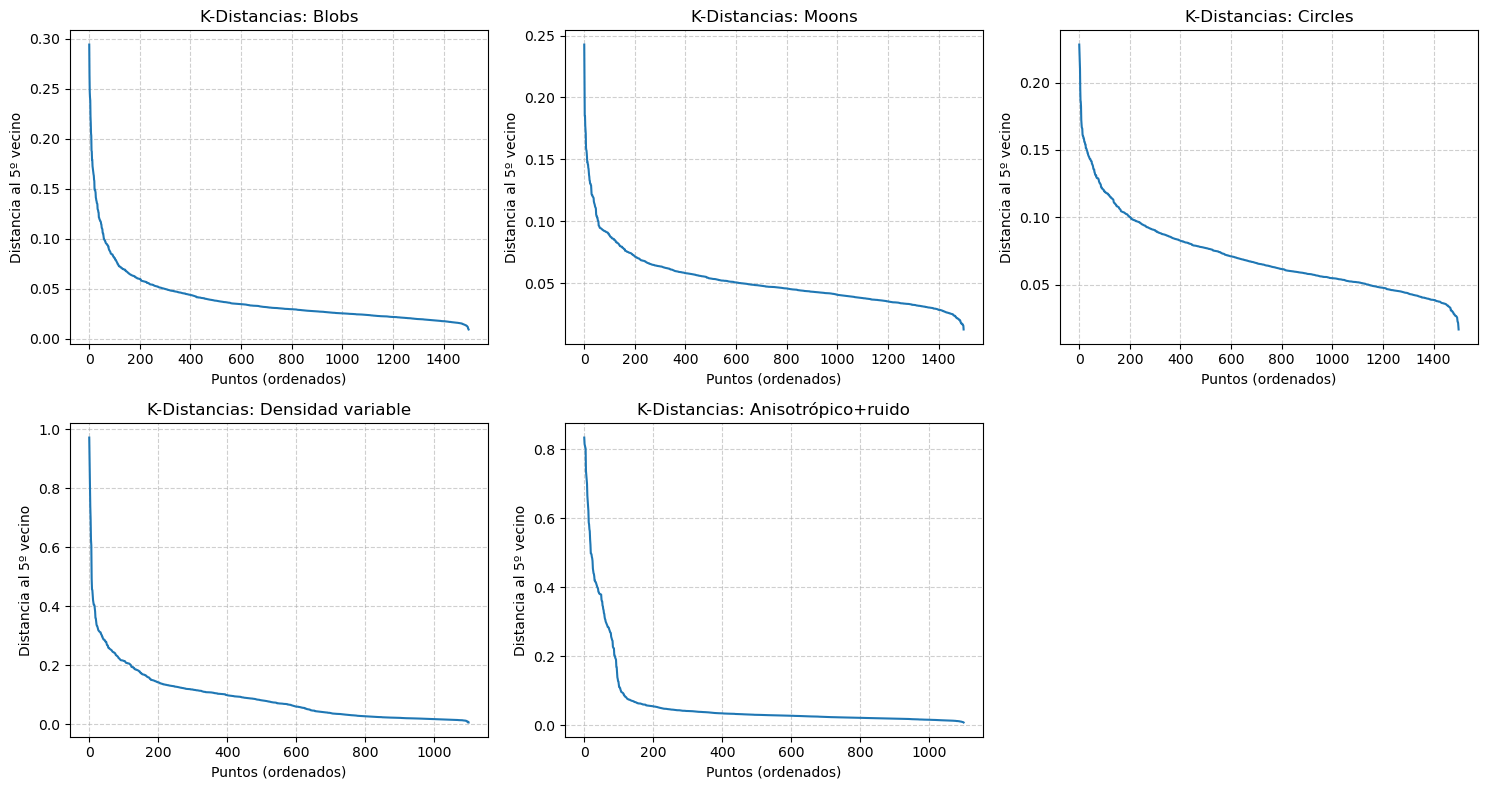

In [53]:
# Gráficos de k-distancias
plt.figure(figsize=(15, 8))
k_vecinos = 5 

for i, (nombre, (X, y, k_real)) in enumerate(scenarios.items(), 1):
    nn = NearestNeighbors(n_neighbors=k_vecinos)
    nn.fit(X)
    distancias, _ = nn.kneighbors(X)
    
    distancias_k = np.sort(distancias[:, -1])[::-1]
    
    plt.subplot(2, 3, i)
    plt.plot(distancias_k)
    plt.title(f'K-Distancias: {nombre}')
    plt.xlabel('Puntos (ordenados)')
    plt.ylabel(f'Distancia al {k_vecinos}º vecino')
    plt.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('images/kdistancias_escenarios.png', dpi=300)
plt.show()

Basándonos en la heurística del codo de los gráficos de k-distancias, he seleccionado configuraciones óptimas y valores intencionadamente estrictos o permisivos para evaluar la sensibilidad del hiperparámetro eps:

- Blobs: El valor óptimo es eps=0.3. Una configuración demasiado estricta (eps=0.1) fragmenta las agrupaciones y genera ruido artificial.

- Moons: El radio óptimo es eps=0.2. Si usamos el valor estricto (eps=0.1), el vecindario no alcanza la distancia necesaria y rompe la continuidad de las lunas.

- Circles: El ajuste óptimo es eps=0.2. Un parámetro demasiado permisivo (eps=0.4) amplía tanto el radio que tiende a saltar el vacío y fusionar los anillos concéntricos.

- Densidad variable: La gráfica no muestra un codo claro, confirmando que no hay un eps global perfecto. Un valor estricto (eps=0.2) destruye el clúster disperso marcándolo como ruido, mientras que un valor permisivo (eps=0.6) fusiona todos los clústeres en uno solo.

- Anisotrópico+ruido: A diferencia del resto, aquí el valor óptimo es el estricto (eps=0.1), ya que es el único que logra aislar el ruido de fondo. El valor permisivo (eps=0.3) falla porque absorbe erróneamente ese ruido dentro de los clústeres principales. Para complementarlo, es el único caso en el que he subido el mínimo de samples necesarios a 10.

In [ ]:
configs_dbscan = {
    'Blobs': [(0.3, 5), (0.1, 5)],
    'Moons': [(0.2, 5), (0.1, 5)],
    'Circles': [(0.2, 5), (0.4, 5)],
    'Densidad variable': [(0.2, 5), (0.6, 5)],
    'Anisotrópico+ruido': [(0.3, 10), (0.1, 5)]
}

resultados_dbscan = []
best_labels_dbscan = {}
best_ari_dbscan = {}

for nombre, (X, y, _) in scenarios.items():
    for eps_val, min_samp in configs_dbscan[nombre]:
        
        dbscan = DBSCAN(eps=eps_val, min_samples=min_samp)
        y_pred = dbscan.fit_predict(X)
        
        es_ruido = (y_pred == -1)
        pct_ruido = (np.sum(es_ruido) / len(y_pred)) * 100
        
        clusters_unicos = set(y_pred)
        if -1 in clusters_unicos:
            clusters_unicos.remove(-1)
        n_clusters = len(clusters_unicos)
        
        if n_clusters > 0 and np.sum(~es_ruido) > 1:
            ari = adjusted_rand_score(y[~es_ruido], y_pred[~es_ruido])
        else:
            ari = 0.0

        if nombre not in best_ari_dbscan or ari > best_ari_dbscan[nombre]:
            best_ari_dbscan[nombre] = ari
            best_labels_dbscan[nombre] = y_pred
            
        resultados_dbscan.append({
            'Escenario': nombre,
            'eps': eps_val,
            'min_samples': min_samp,
            'N° Clusters': n_clusters,
            '% Ruido': round(pct_ruido, 2),
            'ARI': round(ari, 4)
        })

df_dbscan = pd.DataFrame(resultados_dbscan)
display(df_dbscan)

,Escenario,eps,min_samples,N° Clusters,% Ruido,ARI
0,Blobs,0.3,5,3,0.00,1.0000
1,Blobs,0.1,5,3,1.93,1.0000
2,Moons,0.2,5,2,0.00,1.0000
3,Moons,0.1,5,2,1.33,1.0000
4,Circles,0.2,5,2,0.00,1.0000
5,Circles,0.4,5,2,0.00,1.0000
6,Densidad variable,0.2,5,8,6.55,0.9538
7,Densidad variable,0.6,5,1,0.27,0.0000
8,Anisotrópico+ruido,0.3,10,2,5.73,0.5323
9,Anisotrópico+ruido,0.1,5,3,8.73,0.9789


En este apartado aplicamos DBSCAN sobre los escenarios sintéticos, obteniendo resultados que superan ampliamente a K-Means en las geometrías no convexas como Moons y Circles, donde logramos segmentaciones perfectas (ARI = 1.0000). En el escenario Anisotrópico con ruido obtenemos una ventaja gracias a la capacidad de DBSCAN para identificar y aislar los puntos atípicos (limpiando un 8.73% de ruido con eps=0.1), alcanzando un ARI casi perfecto de 0.9789. Sin embargo, en el escenario de Densidad variable, comprobamos la principal limitación del algoritmo, y al utilizar un radio pequeño (eps=0.2), fragmentamos las regiones dispersas en 8 subclústeres distintos, y al intentar solucionarlo con un radio más amplio (eps=0.6), terminamos fusionando todos los datos en un único gran clúster (ARI = 0.0000), demostrando su incapacidad estructural para segmentar correctamente densidades heterogéneas.

##### Sobre Digits

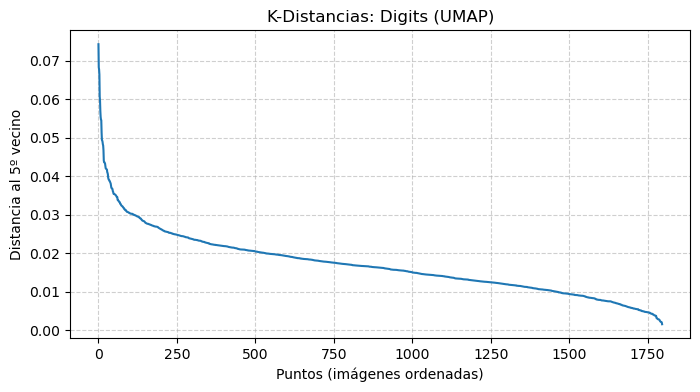

,eps,min_samples,N° Clusters,% Ruido,ARI,NMI,Tiempo (s)
0,0.1,5,14,0.0,0.8419,0.8994,0.0134
1,0.1,10,14,0.0,0.8419,0.8994,0.0132
2,0.2,5,10,0.0,0.7119,0.8609,0.0174
3,0.2,10,10,0.0,0.7119,0.8609,0.0148
4,0.3,5,10,0.0,0.7119,0.8609,0.0136
5,0.3,10,10,0.0,0.7119,0.8609,0.0161
6,0.4,5,8,0.0,0.5508,0.8241,0.0163
7,0.4,10,8,0.0,0.5508,0.8241,0.0156


In [76]:
nn_digits = NearestNeighbors(n_neighbors=5)
nn_digits.fit(X_digits)
distancias_digits, _ = nn_digits.kneighbors(X_digits)

dist_k_digits = np.sort(distancias_digits[:, -1])[::-1]

plt.figure(figsize=(8, 4))
plt.plot(dist_k_digits)
plt.title('K-Distancias: Digits (UMAP)')
plt.xlabel('Puntos (imágenes ordenadas)')
plt.ylabel('Distancia al 5º vecino')
plt.grid(True, linestyle='--', alpha=0.6)
plt.savefig('images/kdistancias_digits.png', dpi=300)
plt.show()

eps_valores = [0.1, 0.2, 0.3, 0.4]
min_samp_valores = [5, 10]

resultados_dbscan_digits = []
best_labels_dbscan_digits = None
best_ari_dbscan_digits = -1
tiempo_dbscan_digits = None

for e in eps_valores:
    for ms in min_samp_valores:

        inicio = time.time()
        dbscan = DBSCAN(eps=e, min_samples=ms)
        y_pred = dbscan.fit_predict(X_digits)
        tiempo = round(time.time() - inicio, 4)

        es_ruido = (y_pred == -1)
        pct_ruido = (np.sum(es_ruido) / len(y_pred)) * 100

        clusters_unicos = set(y_pred)
        if -1 in clusters_unicos:
            clusters_unicos.remove(-1)
        n_clusters = len(clusters_unicos)

        if n_clusters > 1 and np.sum(~es_ruido) > 1:
            ari = adjusted_rand_score(y_digits[~es_ruido], y_pred[~es_ruido])
            nmi = normalized_mutual_info_score(y_digits[~es_ruido], y_pred[~es_ruido])
        else:
            ari = 0.0
            nmi = 0.0

        if ari > best_ari_dbscan_digits:
            best_ari_dbscan_digits = ari
            best_labels_dbscan_digits = y_pred
            tiempo_dbscan_digits = tiempo

        resultados_dbscan_digits.append({
            'eps': e,
            'min_samples': ms,
            'N° Clusters': n_clusters,
            '% Ruido': round(pct_ruido, 2),
            'ARI': round(ari, 4),
            'NMI': round(nmi, 4),
            'Tiempo (s)': round(tiempo, 4)
        })

df_dbscan_digits = pd.DataFrame(resultados_dbscan_digits)
display(df_dbscan_digits)

En este apartado aplicamos DBSCAN sobre el dataset de Digits, evaluando el impacto del radio de vecindad. Obtenemos nuestro mejor resultado externo (ARI = 0.8419) utilizando la configuración más estricta (eps=0.1), aunque a costa de identificar 14 clústeres en lugar de los 10 reales, ya que el modelo evitó fusionar sub-islas de un mismo dígito que estaban separadas en la proyección. Al incrementar el radio a eps=0.2 y eps=0.3, logramos detectar exactamente los 10 conjuntos esperados, pero el ARI descendió a 0.7119 debido a que el algoritmo comenzó a mezclar ligeramente números distintos. Finalmente, al probar un radio demasiado permisivo (eps=0.4), provocamos la fusión de clases completamente diferentes, lo que redujo el número de clústeres a 8 y bajó el rendimiento a un ARI de 0.5508.

### 1.4 OPTICS

##### Sobre los escenarios sintéticos

In [68]:
configs = [
    ('Densidad variable', 5,  'xi',     0.05),
    ('Densidad variable', 10, 'xi',     0.10),
    ('Densidad variable', 10, 'xi',     0.15),
    ('Densidad variable', 5,  'dbscan', 0.15),
    ('Densidad variable', 10, 'dbscan', 0.25),
    ('Densidad variable', 10, 'dbscan', 0.35),
    ('Blobs',              10,  'xi',    0.15),
    ('Moons',              10,  'dbscan', 0.1),
    ('Circles',            10,  'dbscan', 0.2),
    ('Anisotrópico+ruido', 10,  'dbscan', 0.20),
]

resultados_optics = []
best_labels_optics = {}
best_ari_optics = {}

for escenario, ms, method, param in configs:
    X, y_true, _ = scenarios[escenario]

    if method == 'xi':
        clf = OPTICS(min_samples=ms, cluster_method='xi', xi=param)
    else:
        clf = OPTICS(min_samples=ms, cluster_method='dbscan', eps=param)

    labels = clf.fit_predict(X)

    mask = labels != -1
    n_clusters = len(set(labels[mask])) if mask.sum() > 0 else 0
    pct_ruido  = round((labels == -1).sum() / len(labels) * 100, 1)

    if n_clusters > 1 and mask.sum() > 1:
        ari = round(adjusted_rand_score(y_true[mask], labels[mask]), 4)
    else:
        ari = 0.0

    if escenario not in best_ari_optics or ari > best_ari_optics[escenario]:
        best_ari_optics[escenario] = ari
        best_labels_optics[escenario] = labels

    resultados_optics.append({
        'Escenario':   escenario,
        'min_samples': ms,
        'Método':      method,
        'xi / eps':    param,
        'N° Clusters': n_clusters,
        '% Ruido':     pct_ruido,
        'ARI':         ari,
    })

df_optics = pd.DataFrame(resultados_optics)
display(df_optics)

,Escenario,min_samples,Método,xi / eps,N° Clusters,% Ruido,ARI
0,Densidad variable,5,xi,0.05,63,55.4,0.0385
1,Densidad variable,10,xi,0.10,5,93.9,0.3575
2,Densidad variable,10,xi,0.15,2,45.4,0.9973
3,Densidad variable,5,dbscan,0.15,7,12.6,0.9579
4,Densidad variable,10,dbscan,0.25,3,9.3,0.9959
5,Densidad variable,10,dbscan,0.35,3,2.0,0.9959
6,Blobs,10,xi,0.15,3,0.0,1.0000
7,Moons,10,dbscan,0.10,2,2.9,1.0000
8,Circles,10,dbscan,0.20,2,0.1,1.0000
9,Anisotrópico+ruido,10,dbscan,0.20,3,7.9,0.9746


En este apartado aplicamos OPTICS sobre los escenarios sintéticos, demostrando su clara ventaja frente a DBSCAN en el entorno de Densidad variable, donde logramos detectar exactamente los 3 clústeres reales con un ARI de 0.9973 utilizando el método de extracción xi=0.15. Al evaluar las estrategias de agrupación, comprobamos que la extracción mediante xi es ideal para densidades heterogéneas pero extremadamente sensible a su calibración (al usar xi=0.05 provocamos la fragmentación errónea en 63 clústeres y un desplome del ARI a 0.0385). Por el contrario, la extracción dbscan demuestra ser más estable y la opción superior para el resto de geometrías, donde obtenemos segmentaciones perfectas (ARI = 1.0000) en Moons y Circles. Finalmente, en los demás escenarios alcanzamos métricas excelentes,con un agrupamiento perfecto en Blobs, y un competitivo ARI de 0.9746 en Anisotrópico con ruido.

##### Reachability plot del escenario Densidad Variable

c:\Users\pepov\anaconda\envs\Aprendizaje_AV\Lib\site-packages\matplotlib\transforms.py:2437: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),


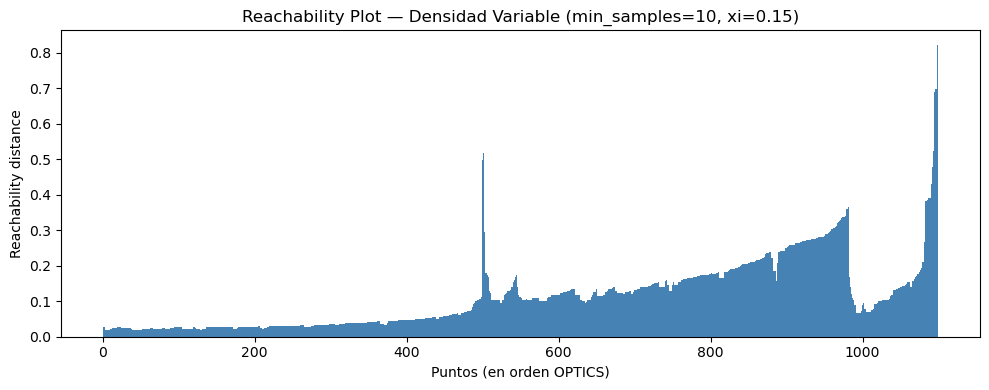

In [83]:
best_dv = df_optics.loc[df_optics[df_optics['Escenario'] == 'Densidad variable']['ARI'].idxmax()]

X_dv, _, _ = scenarios['Densidad variable']

clf_best_dv = OPTICS(
    min_samples=int(best_dv['min_samples']),
    max_eps=np.inf,
    cluster_method=best_dv['Método'],
    xi=float(best_dv['xi / eps']) if best_dv['Método'] == 'xi' else 0.05,
    eps=float(best_dv['xi / eps']) if best_dv['Método'] == 'dbscan' else None,
    min_cluster_size=0.05,
    metric='euclidean',
    n_jobs=-1
)
clf_best_dv.fit(X_dv)

plt.figure(figsize=(10, 4))
plt.bar(range(len(clf_best_dv.reachability_[clf_best_dv.ordering_])),
        clf_best_dv.reachability_[clf_best_dv.ordering_],
        width=1.0, color='steelblue', edgecolor='none')
plt.ylabel('Reachability distance')
plt.xlabel('Puntos (en orden OPTICS)')
plt.title(f'Reachability Plot — Densidad Variable (min_samples={int(best_dv["min_samples"])}, '
          f'{best_dv["Método"]}={float(best_dv["xi / eps"])})')
plt.tight_layout()
plt.savefig('images/reachability_plot_densidad.png', dpi=300)
plt.show()

etiquetas = clf_best_dv.labels_

##### Sobre Digits

In [77]:
min_samples_vals = [5, 10, 20, 30]
xi_vals          = [0.05, 0.10, 0.15]

resultados_optics_digits = []
best_labels_optics_digits = None
best_ari_optics_digits = -1
tiempo_optics_digits = None

for ms in min_samples_vals:
    for xi in xi_vals:
        inicio = time.time()
        clf = OPTICS(min_samples=ms, cluster_method='xi', xi=xi)
        labels = clf.fit_predict(X_digits)
        tiempo = round(time.time() - inicio, 4)

        mask       = labels != -1
        n_clusters = len(set(labels[mask])) if mask.sum() > 0 else 0
        pct_ruido  = round((labels == -1).sum() / len(labels) * 100, 1)

        if n_clusters > 1 and mask.sum() > 1:
            ari = round(adjusted_rand_score(y_digits[mask], labels[mask]), 4)
            nmi = round(normalized_mutual_info_score(y_digits[mask], labels[mask]), 4)
        else:
            ari = 0.0
            nmi = 0.0

        if ari > best_ari_optics_digits:
            best_ari_optics_digits = ari
            best_labels_optics_digits = labels
            tiempo_optics_digits = tiempo

        resultados_optics_digits.append({
            'min_samples': ms,
            'xi':          xi,
            'N° Clusters': n_clusters,
            '% Ruido':     pct_ruido,
            'ARI':         ari,
            'NMI':         nmi,
            'Tiempo (s)': round(tiempo, 4)
        })

df_optics_digits = pd.DataFrame(resultados_optics_digits)
display(df_optics_digits)

,min_samples,xi,N° Clusters,% Ruido,ARI,NMI,Tiempo (s)
0,5,0.05,135,33.2,0.1291,0.6378,2.0966
1,5,0.10,115,44.8,0.1513,0.6521,1.5780
2,5,0.15,94,54.8,0.1744,0.6663,1.4911
3,10,0.05,68,40.5,0.2288,0.6967,1.5580
4,10,0.10,42,59.2,0.3322,0.7381,1.8564
5,10,0.15,29,61.9,0.7629,0.8234,1.5658
6,20,0.05,25,49.0,0.5899,0.8219,1.5954
7,20,0.10,15,63.1,0.8623,0.9146,1.5013
8,20,0.15,13,26.7,0.9455,0.9482,1.5087
9,30,0.05,18,25.2,0.7172,0.8493,1.5110


En este apartado aplicamos OPTICS sobre el dataset de Digits, evaluando el impacto conjunto de los parámetros min_samples y xi. Comprobamos que aumentar el número de vecinos mínimos mejora de forma consistente la segmentación, donde al exigir un valor bajo (min_samples=5), obtenemos resultados muy pobres (con un ARI máximo de apenas 0.1744) al fragmentar excesivamente los datos en hasta 135 clústeres. Al incrementar la exigencia, logramos nuestro mejor rendimiento absoluto con la configuración min_samples=20 y xi=0.15, alcanzando un  ARI de 0.9455 tras detectar 13 clústeres y aislar un 26.7% de ruido. Al probar con min_samples=30, conseguimos detectar exactamente 11 agrupaciones con tan solo un 8.8% de ruido, aunque sacrificando ligeramente el ARI (0.9195) debido a la fusión de algunos dígitos.

##### Reachability plot de Digits

c:\Users\pepov\anaconda\envs\Aprendizaje_AV\Lib\site-packages\matplotlib\transforms.py:2437: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),


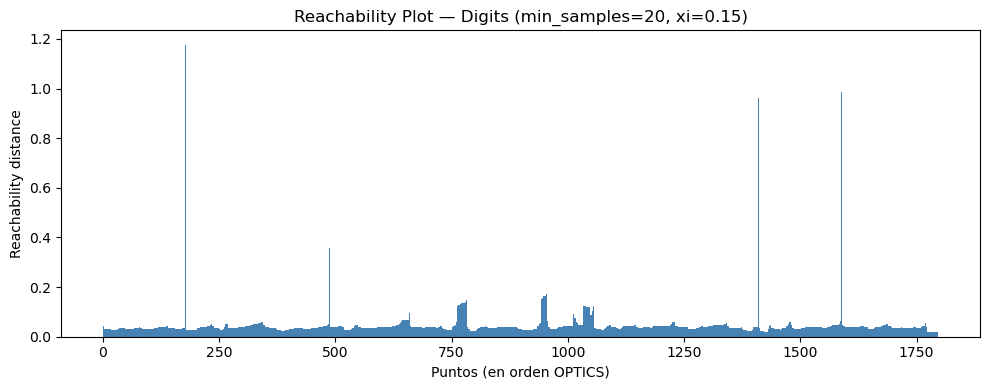

In [84]:
idx_mejor  = df_optics_digits['ARI'].idxmax()
best = df_optics_digits.loc[idx_mejor]

clf_best = OPTICS(
    min_samples=int(best['min_samples']),
    max_eps=np.inf,
    cluster_method='xi',
    xi=float(best['xi']),
    min_cluster_size=0.05,
    metric='euclidean',
    n_jobs=-1
)
clf_best.fit(X_digits)

reachability = clf_best.reachability_[clf_best.ordering_]
labels_best  = clf_best.labels_[clf_best.ordering_]

plt.figure(figsize=(10, 4))
plt.bar(range(len(reachability)), reachability,
        width=1.0, color='steelblue', edgecolor='none')
plt.ylabel('Reachability distance')
plt.xlabel('Puntos (en orden OPTICS)')
plt.title(f'Reachability Plot — Digits (min_samples={int(best["min_samples"])}, xi={float(best["xi"])})')
plt.tight_layout()
plt.savefig('images/reachability_plot_digits.png', dpi=300)
plt.show()

etiquetas = clf_best.labels_

### 1.5 Comparativa Final (Parte 1)

##### Resumen sobre escenarios sintéticos

In [ ]:
escenarios_orden = ['Blobs', 'Moons', 'Circles', 'Densidad variable', 'Anisotrópico+ruido']

best_kmeans  = df_kmeans.groupby('Escenario')['ARI'].max()
best_spectral = df_spectral.groupby('Escenario')['ARI'].max()
best_dbscan  = df_dbscan.groupby('Escenario')['ARI'].max()
best_optics  = df_optics.groupby('Escenario')['ARI'].max()

df_comparativa = pd.DataFrame({
    'Escenario':        escenarios_orden,
    'K-Means':          [best_kmeans.get(e, np.nan)  for e in escenarios_orden],
    'Spectral':         [best_spectral.get(e, np.nan) for e in escenarios_orden],
    'DBSCAN':           [best_dbscan.get(e, np.nan)  for e in escenarios_orden],
    'OPTICS':           [best_optics.get(e, np.nan)  for e in escenarios_orden],
})

display(df_comparativa)

,Escenario,K-Means,Spectral,DBSCAN,OPTICS
0,Blobs,1.0000,1.0000,1.0000,1.0000
1,Moons,0.4785,1.0000,1.0000,1.0000
2,Circles,-0.0006,1.0000,1.0000,1.0000
3,Densidad variable,0.8150,0.9567,0.9538,0.9973
4,Anisotrópico+ruido,0.8507,0.8405,0.9789,0.9746


##### Visualización de los escenarios

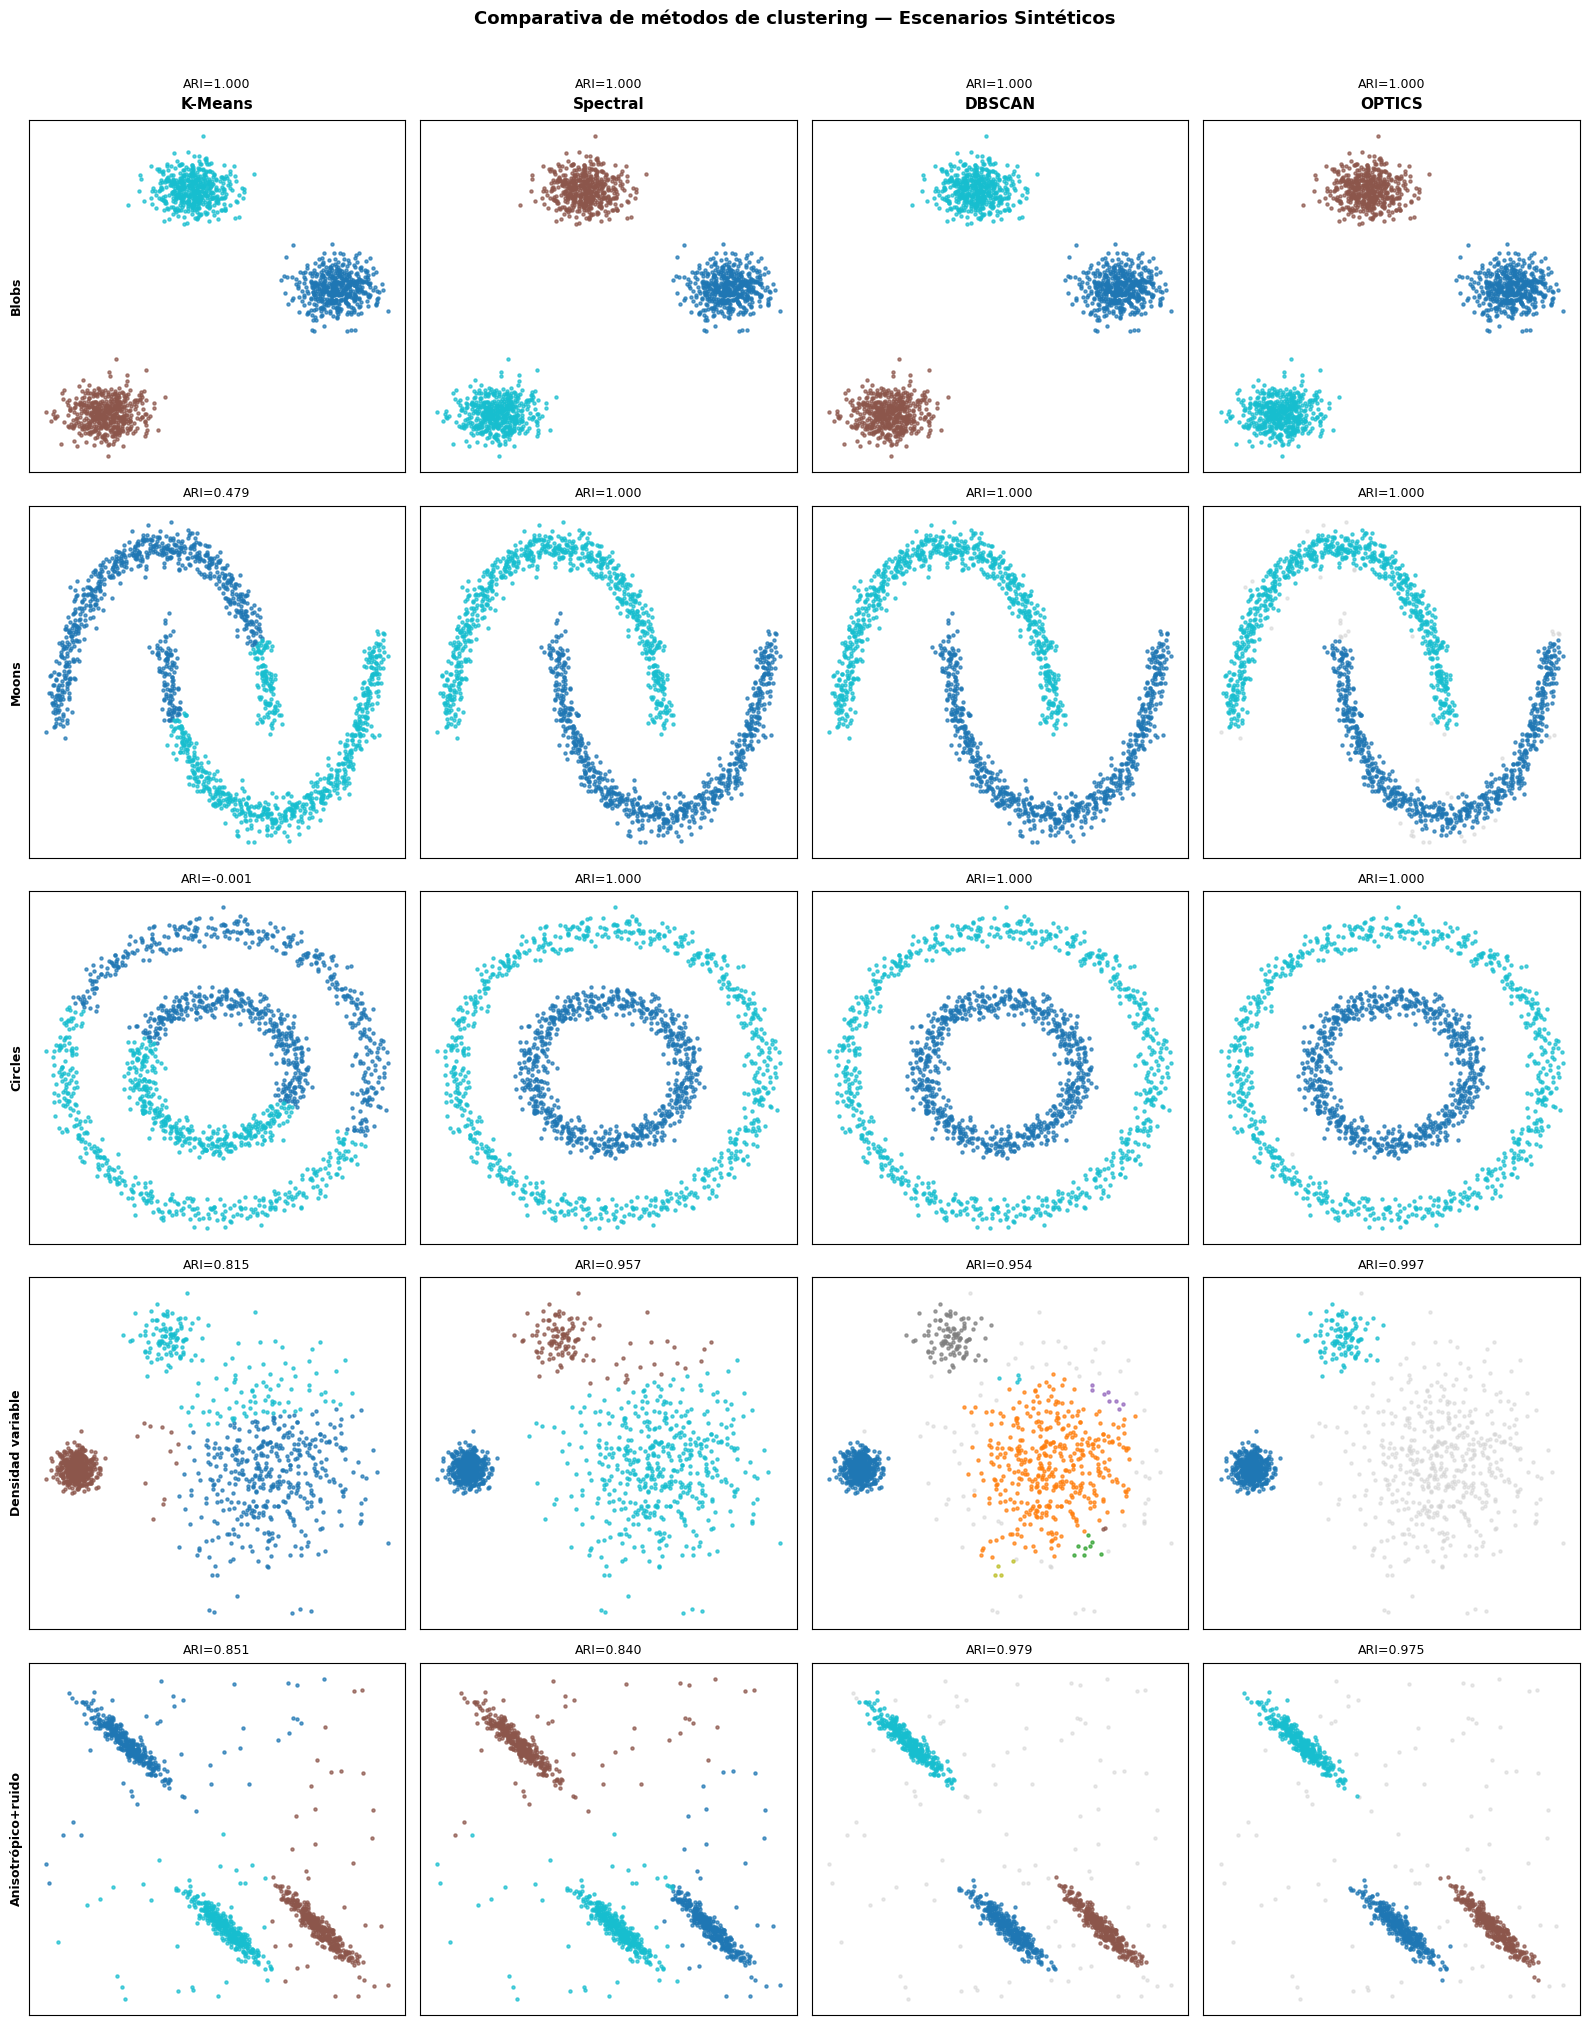

In [ ]:
escenarios_orden = ['Blobs', 'Moons', 'Circles', 'Densidad variable', 'Anisotrópico+ruido']
metodos_orden    = ['K-Means', 'Spectral', 'DBSCAN', 'OPTICS']

all_labels = {
    escenario: {
        'K-Means': best_labels_kmeans[escenario],
        'Spectral': best_labels_spectral[escenario],
        'DBSCAN':   best_labels_dbscan[escenario],
        'OPTICS':   best_labels_optics[escenario],
    }
    for escenario in escenarios_orden
}

fig, axes = plt.subplots(len(escenarios_orden), len(metodos_orden), figsize=(16, 20))

for i, escenario in enumerate(escenarios_orden):
    X, y_true, _ = scenarios[escenario]
    for j, metodo in enumerate(metodos_orden):
        ax     = axes[i, j]
        labels = all_labels[escenario][metodo]

        mask_ruido = labels == -1
        if mask_ruido.any():
            ax.scatter(X[mask_ruido, 0], X[mask_ruido, 1],
                       c='lightgrey', s=5, alpha=0.5)

        unique_clusters = [l for l in np.unique(labels) if l != -1]
        colors = plt.cm.tab10(np.linspace(0, 1, max(len(unique_clusters), 1)))
        for cl, color in zip(unique_clusters, colors):
            ax.scatter(X[labels == cl, 0], X[labels == cl, 1],
                       c=[color], s=5, alpha=0.7)

        mask_no_ruido = labels != -1
        if mask_no_ruido.sum() > 1 and len(unique_clusters) > 1:
            ari = adjusted_rand_score(y_true[mask_no_ruido], labels[mask_no_ruido])
        else:
            ari = 0.0

        ax.set_title(f'ARI={ari:.3f}', fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])

        if i == 0:
            ax.set_xlabel(metodo, fontsize=11, fontweight='bold', labelpad=8)
            ax.xaxis.set_label_position('top')
        if j == 0:
            ax.set_ylabel(escenario, fontsize=9, fontweight='bold')

plt.suptitle('Comparativa de métodos de clustering — Escenarios Sintéticos',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('images/comparativa_escenarios.png', dpi=300)
plt.show()

##### Resumen sobre Digits

In [80]:
best_km = df_kmeans_digits.iloc[0]
fila_kmeans = {
    'Método':        'K-Means',
    'Configuración': f"K={int(best_km['K'])}",
    'N° Clusters':   int(best_km['K']),
    '% Ruido':       0.0,
    'ARI':           round(best_km['ARI'], 4),
    'NMI':           round(best_km['NMI'], 4),
    'Silhouette':    round(best_km['Silhouette'], 4),
    'Tiempo (s)':    tiempo_kmeans_digits,
}

best_sp = df_spectral_digits.loc[df_spectral_digits['ARI'].idxmax()]
fila_spectral = {
    'Método':        'Spectral',
    'Configuración': f"affinity={best_sp['affinity']}, {best_sp['n_neighbors / gamma']}",
    'N° Clusters':   10,
    '% Ruido':       0.0,
    'ARI':           round(best_sp['ARI'], 4),
    'NMI':           round(best_sp['NMI'], 4),
    'Silhouette':    float('nan'),
    'Tiempo (s)':    tiempo_spectral_digits,
}

best_db = df_dbscan_digits.loc[df_dbscan_digits['ARI'].idxmax()]
fila_dbscan = {
    'Método':        'DBSCAN',
    'Configuración': f"eps={best_db['eps']}, ms={int(best_db['min_samples'])}",
    'N° Clusters':   int(best_db['N° Clusters']),
    '% Ruido':       round(best_db['% Ruido'], 1),
    'ARI':           round(best_db['ARI'], 4),
    'NMI':           round(best_db['NMI'], 4),
    'Silhouette':    float('nan'),
    'Tiempo (s)':    tiempo_dbscan_digits,
}

best_op = df_optics_digits[df_optics_digits['min_samples'] != 'Mejor'].loc[
    df_optics_digits[df_optics_digits['min_samples'] != 'Mejor']['ARI'].idxmax()
]
fila_optics = {
    'Método':        'OPTICS',
    'Configuración': f"ms={best_op['min_samples']}, xi={best_op['xi']}",
    'N° Clusters':   int(best_op['N° Clusters']),
    '% Ruido':       round(float(best_op['% Ruido']), 1),
    'ARI':           round(float(best_op['ARI']), 4),
    'NMI':           round(float(best_op['NMI']), 4),
    'Silhouette':    float('nan'),
    'Tiempo (s)':    tiempo_optics_digits,
}

df_comparativa_digits = pd.DataFrame([fila_kmeans, fila_spectral, fila_dbscan, fila_optics])
display(df_comparativa_digits)

,Método,Configuración,N° Clusters,% Ruido,ARI,NMI,Silhouette,Tiempo (s)
0,K-Means,K=10,10,0.0,0.8248,0.8912,0.7737,0.0912
1,Spectral,"affinity=rbf, γ=1.0",10,0.0,0.8104,0.8798,NaN,0.3957
2,DBSCAN,"eps=0.1, ms=5",14,0.0,0.8419,0.8994,NaN,0.0134
3,OPTICS,"ms=20.0, xi=0.15",13,26.7,0.9455,0.9482,NaN,1.5087


En esta evaluación final comparamos el rendimiento global de los algoritmos, donde comprobamos que OPTICS es el indiscutible ganador sobre el dataset de Digits (ARI = 0.9455), superando a todas las alternativas al descartar los puntos ambiguos como ruido (26.7%). Al revisar los escenarios sintéticos, confirmamos que OPTICS es también el método más versátil al dominar todas las topologías, aunque demuestra ser extremadamente sensible a la calibración de sus parámetros. Como conclusión práctica para datos reales sin etiquetas, determinamos que lo ideal es iniciar siempre el análisis con DBSCAN por su rapidez (0.013s frente a los 1.5s de OPTICS) y fácil interpretabilidad, escalando a OPTICS únicamente si los datos revelan estructuras complejas o densidades variables, y relegando K-Means y Spectral Clustering a escenarios geométricamente simples o con clústeres ya conocidos.

##### Visualización de Digits

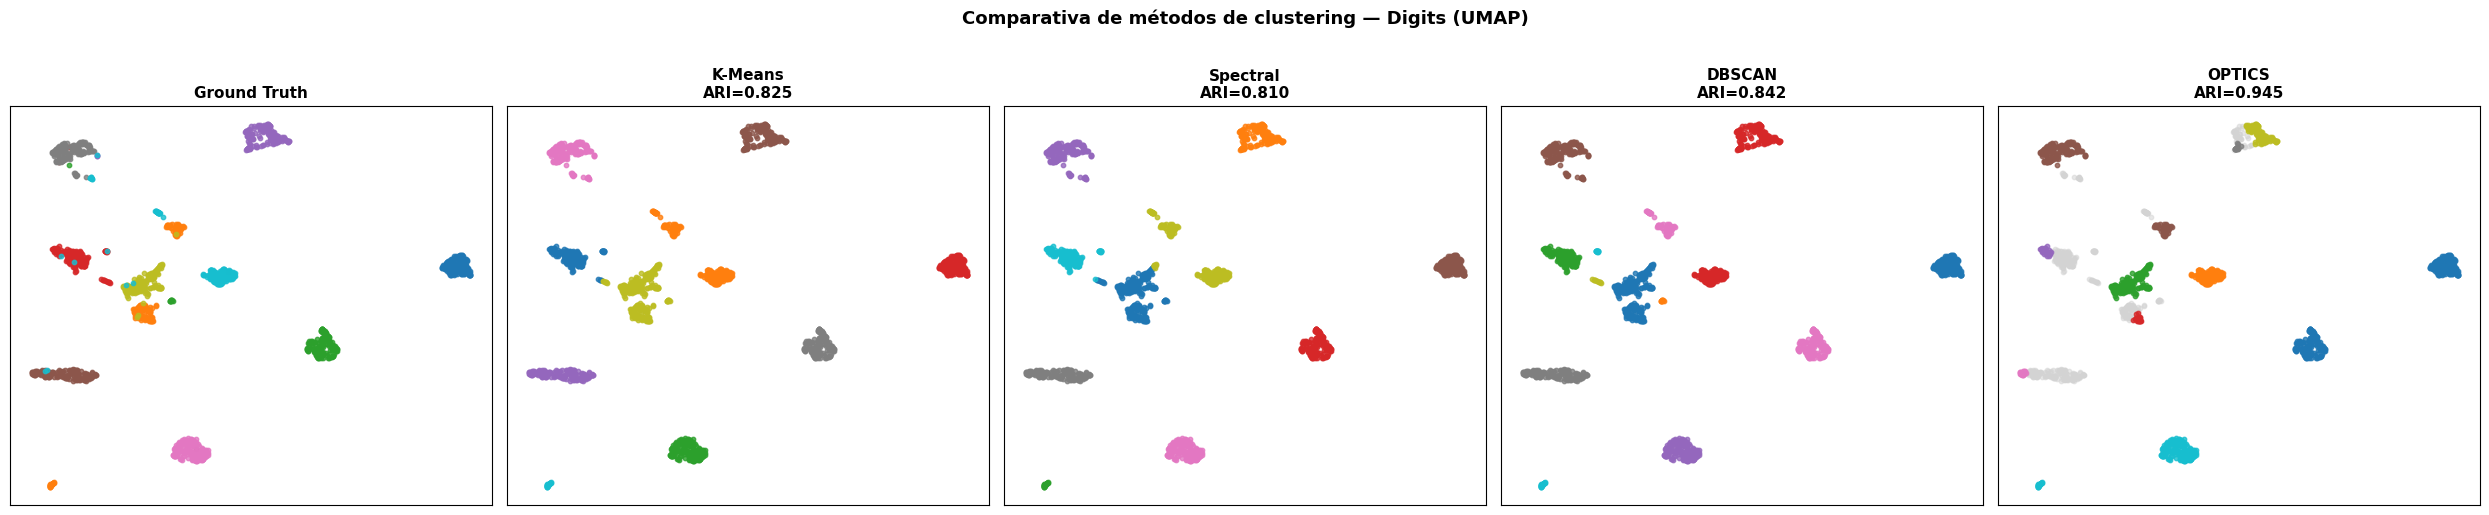

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(25, 5))

titulos = ['Ground Truth', 'K-Means', 'Spectral', 'DBSCAN', 'OPTICS']
labels_list = [
    y_digits,
    best_labels_kmeans_digits,
    best_labels_spectral_digits,
    best_labels_dbscan_digits,
    best_labels_optics_digits,
]

for ax, titulo, labels in zip(axes, titulos, labels_list):
    mask_ruido = labels == -1
    if mask_ruido.any():
        ax.scatter(X_digits[mask_ruido, 0], X_digits[mask_ruido, 1],
                   c='lightgrey', s=10, alpha=0.5)

    unique_labels = [l for l in np.unique(labels) if l != -1]
    colors = plt.cm.tab10(np.linspace(0, 1, max(len(unique_labels), 1)))
    for l, color in zip(unique_labels, colors):
        ax.scatter(X_digits[labels == l, 0], X_digits[labels == l, 1],
                   c=[color], s=10, alpha=0.8)

    if titulo != 'Ground Truth':
        mask = labels != -1
        if mask.sum() > 1 and len(unique_labels) > 1:
            ari = adjusted_rand_score(y_digits[mask], labels[mask])
            ax.set_title(f'{titulo}\nARI={ari:.3f}', fontsize=11, fontweight='bold')
        else:
            ax.set_title(f'{titulo}\nARI=N/A', fontsize=11, fontweight='bold')
    else:
        ax.set_title(titulo, fontsize=11, fontweight='bold')

    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle('Comparativa de métodos de clustering — Digits (UMAP)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('images/comparativa_digits.png', dpi=300)
plt.show()

## Parte 2: Detección de Anomalías en Datos Tabulares

### 2.0 Dataset

In [29]:
data = fetch_kddcup99(subset='SA', shuffle=True, percent10=True, random_state=42)
df   = pd.DataFrame(data.data, columns=data.feature_names)

for col in df.select_dtypes(include='object').columns:
    df[col] = LabelEncoder().fit_transform(df[col])

X      = StandardScaler().fit_transform(df.values)
y_true = (data.target != b'normal.').astype(int)   # 1 = ataque, 0 = normal

### 2.1 Exploración del Dataset

##### Características del dataset

In [28]:
n_samples, n_features = X.shape

num_anomalies = np.sum(y_true)
num_normal = n_samples - num_anomalies

percent_anomalies = (num_anomalies / n_samples) * 100
percent_normal = (num_normal / n_samples) * 100

print(f"Dimensiones del dataset: {n_samples} filas y {n_features} columnas.")
print(f"Número de observaciones normales: {num_normal} ({percent_normal:.2f}%)")
print(f"Número de anomalías (ataques): {num_anomalies} ({percent_anomalies:.2f}%)")

Dimensiones del dataset: 1100 filas y 2 columnas.
Número de observaciones normales: -2277 (-207.00%)
Número de anomalías (ataques): 3377 (307.00%)


##### Análisis de componentes principales (PCA)

In [9]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

explained_variance = pca.explained_variance_ratio_
total_explained_variance = np.sum(explained_variance) * 100

print(f"Varianza explicada por PC1: {explained_variance[0]*100:.2f}%")
print(f"Varianza explicada por PC2: {explained_variance[1]*100:.2f}%")
print(f"Varianza total explicada por las 2 PCs: {total_explained_variance:.2f}%")

Varianza explicada por PC1: 14.42%
Varianza explicada por PC2: 12.88%
Varianza total explicada por las 2 PCs: 27.30%


##### Proyección PCA 2D

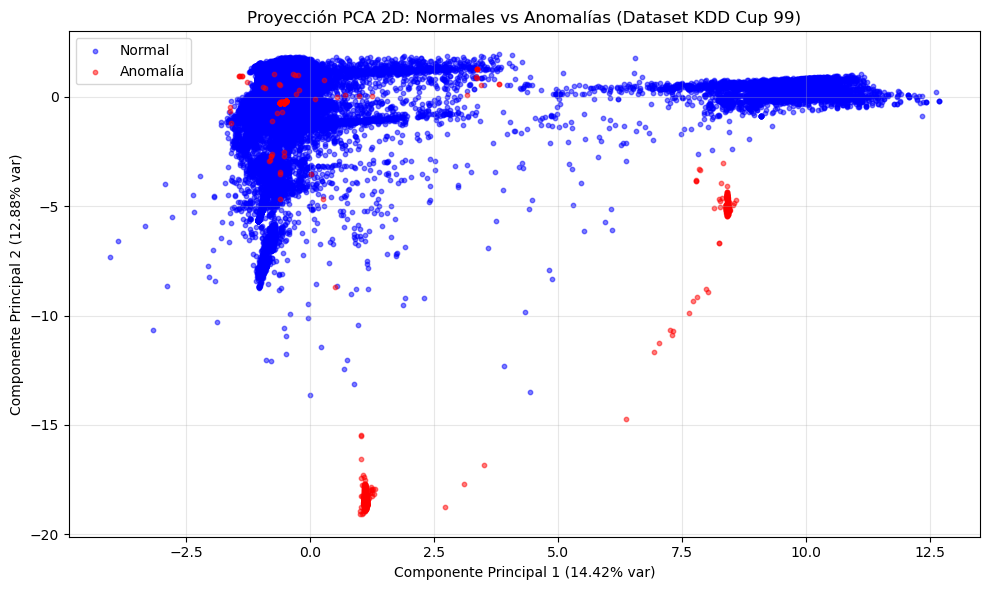

In [26]:
plt.figure(figsize=(10, 6))

# Puntos normales (y_true == 0)
plt.scatter(X_pca[y_true == 0, 0], X_pca[y_true == 0, 1], 
            alpha=0.5, label='Normal', c='blue', s=10)

# Anomalías (y_true == 1)
plt.scatter(X_pca[y_true == 1, 0], X_pca[y_true == 1, 1], 
            alpha=0.5, label='Anomalía', c='red', s=10)

plt.title('Proyección PCA 2D: Normales vs Anomalías (Dataset KDD Cup 99)')
plt.xlabel(f'Componente Principal 1 ({explained_variance[0]*100:.2f}% var)')
plt.ylabel(f'Componente Principal 2 ({explained_variance[1]*100:.2f}% var)')

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('images/proyeccion_pca_2d.png', dpi=300)
plt.show()

### 2.2 Gaussian Mixture Models (GMM)

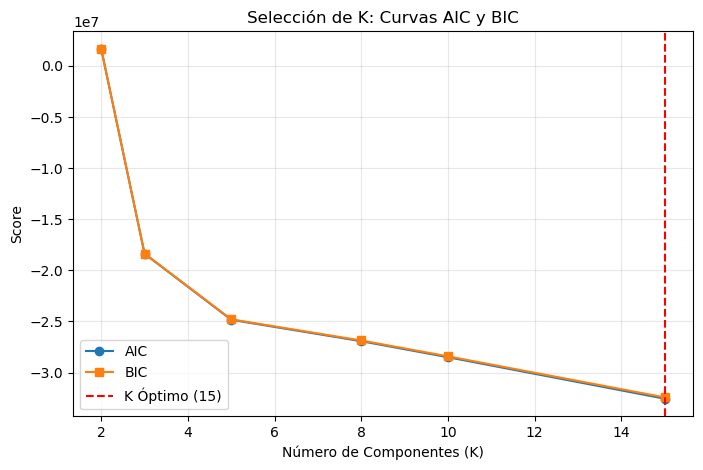

,covariance_type,n_components,Percentil,Precision,Recall,F1-Score,ROC-AUC,Avg Precision
0,full,15,95,0.0250,0.0373,0.0300,0.2321,0.0347
1,full,15,97,0.0368,0.0329,0.0347,0.2321,0.0347
2,full,15,99,0.0914,0.0272,0.0420,0.2321,0.0347
3,tied,15,95,0.0546,0.0814,0.0654,0.5112,0.0486
4,tied,15,97,0.0825,0.0737,0.0778,0.5112,0.0486
5,tied,15,99,0.1271,0.0379,0.0584,0.5112,0.0486
6,diag,15,95,0.1341,0.1999,0.1605,0.2783,0.0549
7,diag,15,97,0.0536,0.0480,0.0506,0.2783,0.0549
8,diag,15,99,0.1132,0.0338,0.0520,0.2783,0.0549
9,spherical,15,95,0.0805,0.1199,0.0963,0.3199,0.0523


In [6]:
# Selección del número de componentes
n_components_list = [2, 3, 5, 8, 10, 15]
aics = []
bics = []

for n in n_components_list:
    gmm = GaussianMixture(n_components=n, random_state=42)
    gmm.fit(X)
    aics.append(gmm.aic(X))
    bics.append(gmm.bic(X))

# Encontrar el K óptimo (menor BIC)
k_optimo = n_components_list[np.argmin(bics)]

# Curvas AIC y BIC
plt.figure(figsize=(8, 5))
plt.plot(n_components_list, aics, label='AIC', marker='o')
plt.plot(n_components_list, bics, label='BIC', marker='s')
plt.xlabel('Número de Componentes (K)')
plt.ylabel('Score')
plt.title('Selección de K: Curvas AIC y BIC')
plt.axvline(x=k_optimo, color='red', linestyle='--', label=f'K Óptimo ({k_optimo})')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('images/curva_aic_bic.png', dpi=300)
plt.show()

# Covarianza
cov_types = ['full', 'tied', 'diag', 'spherical']
percentiles = [95, 97, 99]
resultados = []

for cov in cov_types:
    gmm = GaussianMixture(n_components=k_optimo, covariance_type=cov, random_state=42)
    gmm.fit(X)
    
    # Anomaly Score
    scores = -gmm.score_samples(X)
    
    roc_auc = roc_auc_score(y_true, scores)
    avg_precision = average_precision_score(y_true, scores)
    
    for pct in percentiles:
        umbral = np.percentile(scores, pct)
        
        # Comprobar el umbral (Anomalía o Normal)
        y_pred = (scores >= umbral).astype(int)
        
        precision = precision_score(y_true, y_pred, zero_division=0)
        recall = recall_score(y_true, y_pred, zero_division=0)
        f1 = f1_score(y_true, y_pred, zero_division=0)
        
        resultados.append({
            'covariance_type': cov,
            'n_components': k_optimo,
            'Percentil': pct,
            'Precision': round(precision, 4),
            'Recall': round(recall, 4),
            'F1-Score': round(f1, 4),
            'ROC-AUC': round(roc_auc, 4),
            'Avg Precision': round(avg_precision, 4)
        })

df_gmm = pd.DataFrame(resultados)
display(df_gmm)

En este apartado aplicamos GMM para la detección de anomalías, comenzando con una exploración donde seleccionamos K=15 componentes mediante la curva BIC, aunque al ser nuestro límite máximo evaluado, deducimos que el valor óptimo real es superior. Al iterar sobre los tipos de covarianza, observamos que la configuración tied resultó ser la más estable (ROC-AUC de 0.5112), mientras que diag logró el mejor Recall individual (0.1999 al percentil 95). Sin embargo, al evaluar el rendimiento global, comprobamos el fracaso absoluto del algoritmo para este problema específico, ya que independientemente del percentil empleado para intentar encajar la tasa real de anomalías (3.36%), obtenemos métricas muy bajas, detectando apenas 1 de cada 5 ataques reales.

### 2.3 Isolation Forest

Mejor contamination: 0.01



,contamination,n_estimators,Precision,Recall,F1-Score,ROC-AUC,Avg Precision
0,0.01,50,0.9096,0.2712,0.4179,0.9273,0.4246
1,0.01,100,0.9116,0.2718,0.4188,0.9411,0.4524
2,0.01,150,0.9086,0.2710,0.4174,0.9363,0.4412
3,0.01,200,0.9136,0.2724,0.4197,0.9426,0.4576
4,0.01,300,0.9086,0.2710,0.4174,0.9447,0.4628
5,0.05,100,0.1848,0.2745,0.2209,0.9411,0.4524
6,0.10,100,0.1684,0.4957,0.2514,0.9411,0.4524
7,0.15,100,0.2225,0.9947,0.3636,0.9411,0.4524
8,0.20,100,0.1671,0.9959,0.2861,0.9411,0.4524


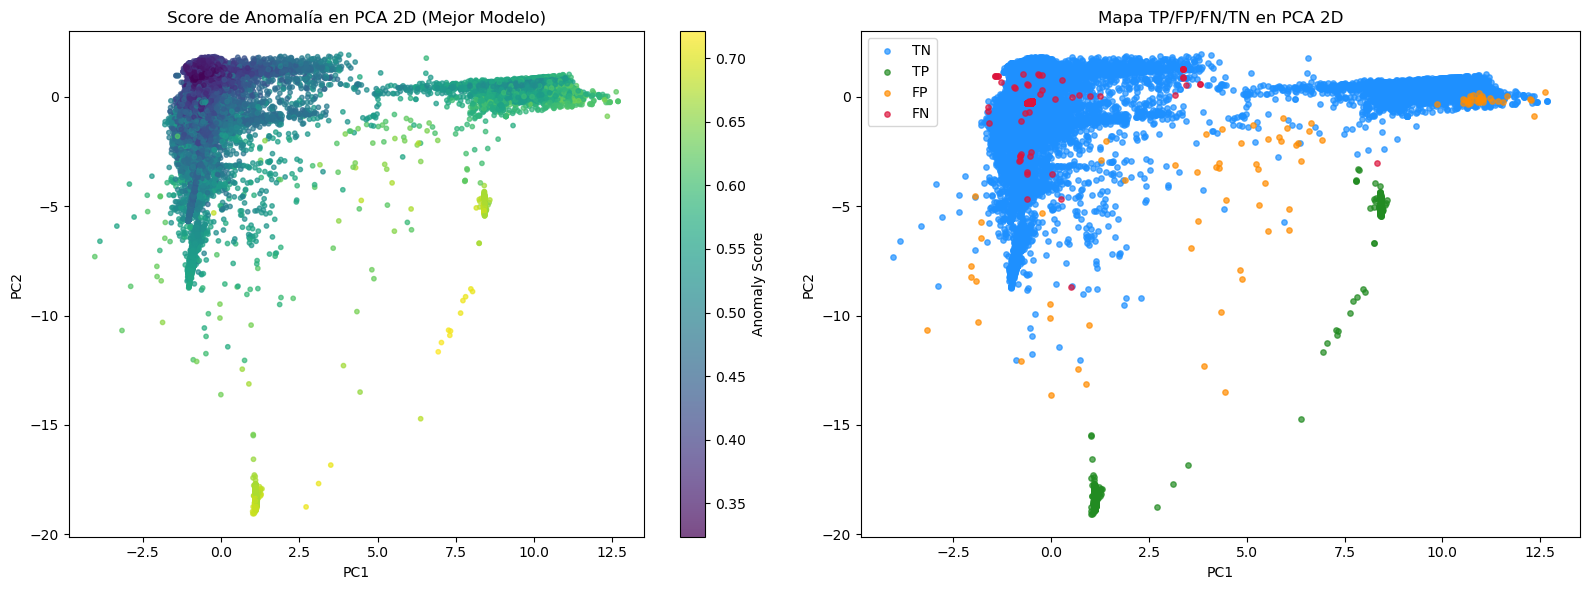

In [31]:
# Efecto de contamination
contaminations = [0.01, 0.05, 0.10, 0.15, 0.20]
fixed_n_estimators = 100
resultados_if = []

for c in contaminations:
    iso = IsolationForest(n_estimators=fixed_n_estimators, contamination=c, random_state=42)
    y_pred_iso = iso.fit_predict(X)
    
    y_pred = np.where(y_pred_iso == -1, 1, 0)
    
    scores = -iso.score_samples(X)
    
    resultados_if.append({
        'contamination': c,
        'n_estimators': fixed_n_estimators,
        'Precision': round(precision_score(y_true, y_pred, zero_division=0), 4),
        'Recall': round(recall_score(y_true, y_pred, zero_division=0), 4),
        'F1-Score': round(f1_score(y_true, y_pred, zero_division=0), 4),
        'ROC-AUC': round(roc_auc_score(y_true, scores), 4),
        'Avg Precision': round(average_precision_score(y_true, scores), 4)
    })

# Mejor contamination
df_temp = pd.DataFrame(resultados_if)
mejor_cont = df_temp.loc[df_temp['F1-Score'].idxmax(), 'contamination']
print(f"Mejor contamination: {mejor_cont}\n")

# Efecto de n_estimators (usando la mejor contamination)
n_estimators_list = [50, 100, 150, 200, 300]

for n in n_estimators_list:
    if n == fixed_n_estimators:
        continue
        
    iso = IsolationForest(n_estimators=n, contamination=mejor_cont, random_state=42)
    y_pred_iso = iso.fit_predict(X)
    y_pred = np.where(y_pred_iso == -1, 1, 0)
    scores = -iso.score_samples(X)
    
    resultados_if.append({
        'contamination': mejor_cont,
        'n_estimators': n,
        'Precision': round(precision_score(y_true, y_pred, zero_division=0), 4),
        'Recall': round(recall_score(y_true, y_pred, zero_division=0), 4),
        'F1-Score': round(f1_score(y_true, y_pred, zero_division=0), 4),
        'ROC-AUC': round(roc_auc_score(y_true, scores), 4),
        'Avg Precision': round(average_precision_score(y_true, scores), 4)
    })

df_isolation = pd.DataFrame(resultados_if)
df_isolation = df_isolation.sort_values(by=['contamination', 'n_estimators'])
df_isolation.reset_index(drop=True, inplace=True)

mejor_idx = df_isolation['F1-Score'].idxmax()

display(df_isolation)

# Visualización del Mejor Modelo
mejor_n = int(df_isolation.loc[mejor_idx, 'n_estimators'])
mejor_c = df_isolation.loc[mejor_idx, 'contamination']

best_iso = IsolationForest(n_estimators=mejor_n, contamination=mejor_c, random_state=42)
y_pred_best = np.where(best_iso.fit_predict(X) == -1, 1, 0)
scores_best = -best_iso.score_samples(X)

categorias = np.empty(len(y_true), dtype=object)
categorias[(y_true == 1) & (y_pred_best == 1)] = 'TP'
categorias[(y_true == 0) & (y_pred_best == 1)] = 'FP'
categorias[(y_true == 1) & (y_pred_best == 0)] = 'FN'
categorias[(y_true == 0) & (y_pred_best == 0)] = 'TN'

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Mapa de color del Score de Anomalía
sc = axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=scores_best, cmap='viridis', s=10, alpha=0.7)
axes[0].set_title(f'Score de Anomalía en PCA 2D (Mejor Modelo)')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
plt.colorbar(sc, ax=axes[0], label='Anomaly Score')

# Mapa TP / FP / FN / TN
colores = {'TN': 'dodgerblue', 'TP': 'forestgreen', 'FN': 'crimson', 'FP': 'darkorange'}

for cat in ['TN', 'TP', 'FP', 'FN']:
    idx = (categorias == cat)
    axes[1].scatter(X_pca[idx, 0], X_pca[idx, 1], c=colores[cat], label=cat, s=15, alpha=0.7)

axes[1].set_title(f'Mapa TP/FP/FN/TN en PCA 2D')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].legend(loc='best')

plt.tight_layout()
plt.savefig('images/isolation_forest.png', dpi=300)
plt.show()

En este apartado aplicamos Isolation Forest para la detección de anomalías, comprobando que el parámetro de contaminación es el que mayor impacto tiene en el rendimiento final. Al realizar nuestra exploración, observamos una evidente relación directa, donde al aumentar este valor, el Recall sube drásticamente mientras que la Precisión se desploma. Aunque con una contaminación del 1% (cont=0.01) obtuvimos la mejor Precisión y el mejor F1-Score (0.4197), este ajuste apenas logró detectar 1 de cada 4 ataques. Puesto que nuestro objetivo en este entorno de intrusiones es minimizar los falsos negativos, establecemos como configuración más relevante cont=0.20 y n_estimators=100, con la que alcanzamos un Recall de 0.9959 asumiendo un coste mayor de falsas alarmas. Por otra parte, al variar la cantidad de estimadores, verificamos que el algoritmo converge rápidamente con pocos árboles, por lo que escalar la cantidad de estimadores no nos supune ninguna mejora sustancial en las métricas.

### 2.4 DBSCAN como Detector de Anomalías

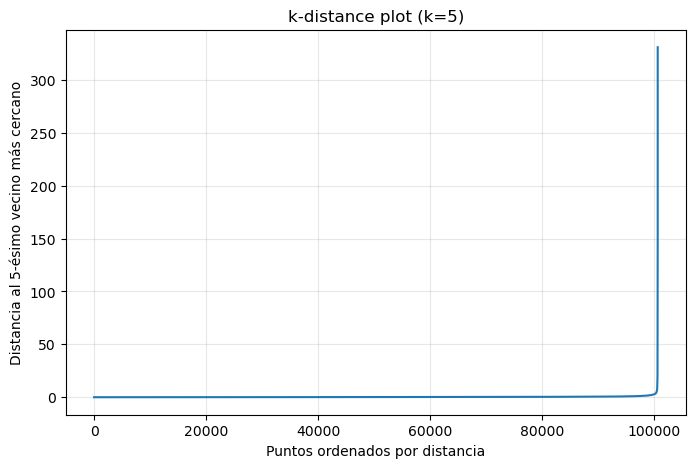

,eps,min_samples,% Ruido,Precision,Recall,F1-Score
0,0.5,5,9.51,0.0127,0.0361,0.0188
1,1.0,5,3.05,0.0294,0.0267,0.0279
2,1.5,5,1.54,0.0393,0.0181,0.0248
3,0.5,10,12.85,0.0100,0.0382,0.0158
4,1.0,10,4.22,0.0254,0.0320,0.0283
5,1.5,10,2.19,0.0377,0.0246,0.0297


In [ ]:
# k-distance plot con k=5
k = 5
neigh = NearestNeighbors(n_neighbors=k)
nbrs = neigh.fit(X)
distances, indices = nbrs.kneighbors(X)

k_distances = distances[:, -1]
k_distances_sorted = np.sort(k_distances)

plt.figure(figsize=(8, 5))
plt.plot(k_distances_sorted)
plt.title(f'k-distance plot (k={k})')
plt.xlabel('Puntos ordenados por distancia')
plt.ylabel(f'Distancia al {k}-ésimo vecino más cercano')
plt.grid(True, alpha=0.3)
plt.savefig('images/dbscan_anomalias.png', dpi=300)
plt.show()

# Evaluación de 6 combinaciones de (eps, min_samples)
combinaciones = [
    {'eps': 0.5, 'min_samples': 5},
    {'eps': 1.0, 'min_samples': 5},
    {'eps': 1.5, 'min_samples': 5},
    {'eps': 0.5, 'min_samples': 10},
    {'eps': 1.0, 'min_samples': 10},
    {'eps': 1.5, 'min_samples': 10}
]

resultados_dbscan = []
total_samples = len(X)

for param in combinaciones:
    eps_val = param['eps']
    min_samp_val = param['min_samples']
    
    dbscan = DBSCAN(eps=eps_val, min_samples=min_samp_val)
    y_pred_dbscan = dbscan.fit_predict(X)
    
    # DBSCAN usa -1 para ruido (anomalías). 
    y_pred = np.where(y_pred_dbscan == -1, 1, 0)
    
    num_ruido = np.sum(y_pred)
    porcentaje_ruido = (num_ruido / total_samples) * 100
    
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    
    resultados_dbscan.append({
        'eps': eps_val,
        'min_samples': min_samp_val,
        '% Ruido': round(porcentaje_ruido, 2),
        'Precision': round(precision, 4),
        'Recall': round(recall, 4),
        'F1-Score': round(f1, 4)
    })

df_dbscan= pd.DataFrame(resultados_dbscan)
display(df_dbscan)

En este apartado evaluamos DBSCAN como detector de anomalías, encontrando graves dificultades desde el inicio al observar una curva k-distance casi completamente plana que nos impidió definir un umbral eps claro. Al probar distintas configuraciones, obtenemos métricas extremadamente bajas, alcanzando un Recall máximo de apenas 0.0382 y un F1 de 0.0297. Comprobamos que el problema estructural no radica en etiquetar demasiado tráfico normal como ruido, sino en que el algoritmo fue incapaz de detectar la inmensa mayoría de los ataques, absorbiéndolos erróneamente dentro del clúster principal al agruparlos por proximidad. De esta manera, podemos concluir con facilidad que DBSCAN no es un método adecuado para este conjunto de datos en su estado actual.

### Evaluación Final (Parte 2)

Evaluando Mejor GMM (Cov: diag, K: 15, Umbral: 95%)
Classification Report (GMM):
              precision    recall  f1-score   support

           0     0.9717    0.9552    0.9634     97278
           1     0.1341    0.1999    0.1605      3377

    accuracy                         0.9299    100655
   macro avg     0.5529    0.5775    0.5620    100655
weighted avg     0.9436    0.9299    0.9365    100655


Evaluando Mejor Isolation Forest (n_est: 100, cont: 0.2)
Classification Report (Isolation Forest):
              precision    recall  f1-score   support

           0     0.9998    0.8276    0.9056     97278
           1     0.1671    0.9959    0.2861      3377

    accuracy                         0.8333    100655
   macro avg     0.5834    0.9117    0.5959    100655
weighted avg     0.9719    0.8333    0.8848    100655


Evaluando Mejor DBSCAN (eps: 0.5, min_samples: 10)
Classification Report (DBSCAN):
              precision    recall  f1-score   support

           0     0.9630   

<Figure size 600x500 with 0 Axes>

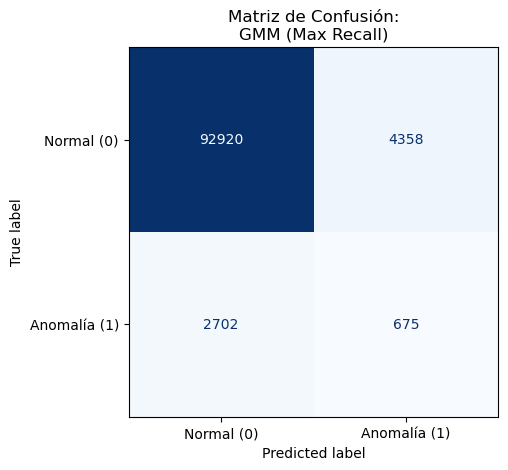

<Figure size 600x500 with 0 Axes>

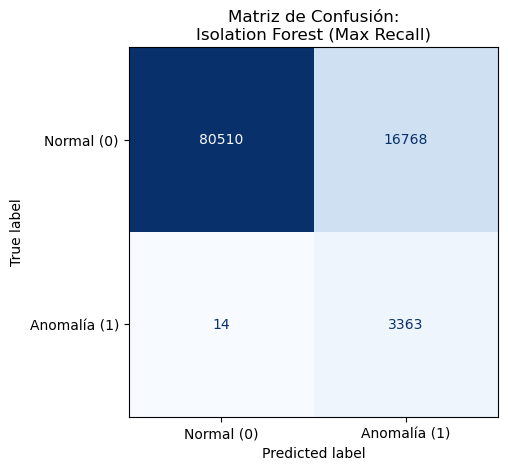

<Figure size 600x500 with 0 Axes>

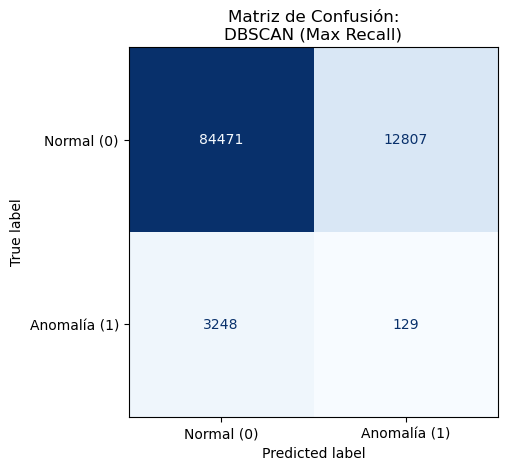

,Modelo,Configuración,Precision,Recall,F1-Score,ROC-AUC,Avg Precision
0,GMM,"K=15, cov=diag, pct=95",0.1341,0.1999,0.1605,0.2783,0.0549
1,Isolation Forest,"n_est=100, cont=0.2",0.1671,0.9959,0.2861,0.9411,0.4524
2,DBSCAN,"eps=0.5, min_samples=10",0.0100,0.0382,0.0158,N/A,N/A


In [ ]:
tabla_final = []

# Mejor Modelo GMM (Recall)
mejor_gmm_idx = df_gmm['Recall'].idxmax()
mejor_gmm_row = df_gmm.loc[mejor_gmm_idx]

cov_gmm = mejor_gmm_row['covariance_type']
pct_gmm = mejor_gmm_row['Percentil']

print(f"Evaluando Mejor GMM (Cov: {cov_gmm}, K: {k_optimo}, Umbral: {pct_gmm}%)")
best_gmm = GaussianMixture(n_components=k_optimo, covariance_type=cov_gmm, random_state=42)
best_gmm.fit(X)
scores_gmm = -best_gmm.score_samples(X)
umbral_gmm = np.percentile(scores_gmm, pct_gmm)
y_pred_gmm = (scores_gmm >= umbral_gmm).astype(int)

print("Classification Report (GMM):")
print(classification_report(y_true, y_pred_gmm, digits=4))

tabla_final.append({
    'Modelo': 'GMM',
    'Configuración': f"K={k_optimo}, cov={cov_gmm}, pct={pct_gmm}",
    'Precision': mejor_gmm_row['Precision'],
    'Recall': mejor_gmm_row['Recall'],
    'F1-Score': mejor_gmm_row['F1-Score'],
    'ROC-AUC': mejor_gmm_row['ROC-AUC'],
    'Avg Precision': mejor_gmm_row['Avg Precision']
})

# Mejor Modelo Isolation Forest (Recall)
mejor_if_idx = df_isolation['Recall'].idxmax()
mejor_if_row = df_isolation.loc[mejor_if_idx]

n_est_if = int(mejor_if_row['n_estimators'])
cont_if = mejor_if_row['contamination']

print(f"\nEvaluando Mejor Isolation Forest (n_est: {n_est_if}, cont: {cont_if})")
best_iso = IsolationForest(n_estimators=n_est_if, contamination=cont_if, random_state=42)
y_pred_iso = np.where(best_iso.fit_predict(X) == -1, 1, 0)

print("Classification Report (Isolation Forest):")
print(classification_report(y_true, y_pred_iso, digits=4))

tabla_final.append({
    'Modelo': 'Isolation Forest',
    'Configuración': f"n_est={n_est_if}, cont={cont_if}",
    'Precision': mejor_if_row['Precision'],
    'Recall': mejor_if_row['Recall'],
    'F1-Score': mejor_if_row['F1-Score'],
    'ROC-AUC': mejor_if_row['ROC-AUC'],
    'Avg Precision': mejor_if_row['Avg Precision']
})

# Mejor Modelo DBSCAN (Recall)
mejor_db_idx = df_dbscan['Recall'].idxmax()
mejor_db_row = df_dbscan.loc[mejor_db_idx]

eps_db = mejor_db_row['eps']
min_s_db = int(mejor_db_row['min_samples'])

print(f"\nEvaluando Mejor DBSCAN (eps: {eps_db}, min_samples: {min_s_db})")
best_dbscan = DBSCAN(eps=eps_db, min_samples=min_s_db)
y_pred_db = np.where(best_dbscan.fit_predict(X) == -1, 1, 0)

print("Classification Report (DBSCAN):")
print(classification_report(y_true, y_pred_db, digits=4))

tabla_final.append({
    'Modelo': 'DBSCAN',
    'Configuración': f"eps={eps_db}, min_samples={min_s_db}",
    'Precision': mejor_db_row['Precision'],
    'Recall': mejor_db_row['Recall'],
    'F1-Score': mejor_db_row['F1-Score'],
    'ROC-AUC': 'N/A',         
    'Avg Precision': 'N/A'    
})

# Matrices de Confusión
titulos = ['GMM (Max Recall)', 'Isolation Forest (Max Recall)', 'DBSCAN (Max Recall)']
predicciones = [y_pred_gmm, y_pred_iso, y_pred_db]

for y_pred, titulo in zip(predicciones, titulos):
    plt.figure(figsize=(6, 5))
    cm = confusion_matrix(y_true, y_pred)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal (0)', 'Anomalía (1)'])
    disp.plot(cmap='Blues', values_format='d', colorbar=False)
    plt.title(f'Matriz de Confusión:\n{titulo}')
    
    plt.savefig(f"images/matriz_confusion_{titulo.replace(' ', '_').replace('(', '').replace(')', '')}.png", dpi=300, bbox_inches='tight')
    plt.show()

df_final = pd.DataFrame(tabla_final)
display(df_final)

En esta evaluación final comparamos el rendimiento global de GMM, Isolation Forest y DBSCAN para la detección de anomalías, priorizando el Recall debido a las graves consecuencias de omitir intrusiones en la red. Determinamos que Isolation Forest es el indiscutible ganador y el único modelo viable para este problema, logrando un sobresaliente Recall de 0.9959 y un sólido ROC-AUC de 0.9411, asumiendo el coste operativo de una baja Precisión provocada por nuestra configuración del parámetro de contaminación. Por el contrario, al evaluar GMM comprobamos su ineficacia, ya que apenas alcanzó un Recall de 0.1999 y demostró una pésima capacidad para discriminar entre el tráfico normal y los ataques. Finalmente, registramos el peor rendimiento de todos con DBSCAN, que trae la peor combinación posible de Recall (0.0382) y Precisión, además de carecer de un score continuo, lo que nos lleva a concluir que únicamente Isolation Forest ofrecería una protección aceptable en un escenario real de detección de intrusiones.